# 05 — Améliorer le modèle 1 sans transfer learning

**Objectif :** améliorer le CNN baseline (`03_model1_baseline.ipynb`) **en restant from scratch**, c'est-à-dire
sans poids pré-entraînés (le transfer learning est testé à part dans le notebook 04).

## Méthode : une étude d'ablation
On part du baseline et on ajoute **une famille d'améliorations à la fois**, de façon **cumulative** :

| Étape | Ajout | Problème du baseline visé |
|---|---|---|
| **e0** | baseline (= `configs/model1.yaml`) | point de référence |
| **e1** | augmentation forte, label smoothing, early stopping, sélection sur le F1 macro | sur-apprentissage (100 % en train dès l'epoch 7) |
| **e2** | recadrage sur le corps | lésions minuscules à 128 px, fond noir et table du scanner inutiles |
| **e3** | MixUp / CutMix, sampler équilibré | mémorisation + biais vers Normal et Cyst |
| **e4** | architecture résiduelle plus profonde | capacité limitée du petit CNN à 4 couches |

Les configs sont dans `configs/model1_ablation/` : chaque fichier marque `# NOUVEAU` ce qui change par rapport à l'étape précédente.

## Pourquoi 3 seeds par étape
Les runs `model1-v1` et `model1-v3` ont exactement la même config, mais leur F1 macro de test va de 0,53 à 0,64.
Avec un seul run, on ne saurait pas si une étape aide vraiment ou si on a eu de la chance. On entraîne donc
chaque étape avec **3 seeds** et on compare les **moyennes ± écarts-types**.

**Durée :** environ 2 h au total sur une GTX 1650 (l'étape e4 est la plus longue). Les runs déjà faits sont
**réutilisés automatiquement** (`REUSE = True`) : relancer le notebook ne réentraîne que ce qui manque.

In [1]:
import os, sys
from pathlib import Path

# Le notebook tourne depuis notebooks/ : on se place à la racine du projet
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import yaml
from PIL import Image
from sklearn.metrics import f1_score

from src import get_model
from src.augment import strong_augment, mixup_cutmix
from src.data import CLASSES, DATA_DIR, list_split_files, load_split, preprocess_image
from src.viz import setup_style, plot_curves, plot_confusion, read_run, SERIES, INK_MUTED
from train import train
from eval import evaluate, predict

setup_style()
print("GPU :", torch.cuda.get_device_name(0))

STEPS = {
    "e0": "configs/model1_ablation/e0_baseline.yaml",
    "e1": "configs/model1_ablation/e1_regul.yaml",
    "e2": "configs/model1_ablation/e2_crop.yaml",
    "e3": "configs/model1_ablation/e3_mix.yaml",
    "e4": "configs/model1_ablation/e4_residual.yaml",
}
STEP_LABELS = {"e0": "e0 baseline", "e1": "e1 +régularisation", "e2": "e2 +recadrage",
               "e3": "e3 +MixUp/sampler", "e4": "e4 +résiduel"}
SEEDS = [42, 43, 44]
REUSE = True   # True : réutilise un run déjà évalué (même étape, même seed) au lieu de réentraîner

GPU : NVIDIA GeForce GTX 1650


In [2]:
def find_run(name, seed):
    """Dernier run évalué results/<name>-s<seed>-vN, ou None."""
    runs = [p for p in Path("results").glob(f"{name}-s{seed}-v*") if (p / "test_output.json").exists()]
    return max(runs, key=lambda p: int(p.name.rsplit("-v", 1)[1])) if runs else None


def run_step(step):
    """Entraîne + évalue une étape pour chaque seed. Retourne un tableau (une ligne par seed)."""
    config = STEPS[step]
    name = yaml.safe_load(Path(config).read_text())["name"]
    rows = []
    for seed in SEEDS:
        run_dir = find_run(name, seed) if REUSE else None
        if run_dir is None:
            run_dir = train(config, seed=seed)
            evaluate(run_dir, verbose=False)
        else:
            print(f"réutilisé : {run_dir}")
        o = json.loads((run_dir / "test_output.json").read_text())
        _, va = read_run(run_dir)
        rows.append({"step": step, "seed": seed, "run": run_dir.name,
                     "epochs": len(va), "val_f1_max": va["f1_macro"].max() if "f1_macro" in va else np.nan,
                     "accuracy": o["accuracy"], "f1_macro": o["f1_macro"],
                     **{f"recall_{c}": v["recall"] for c, v in o["per_class"].items()}})
    return pd.DataFrame(rows)


def show_step(df):
    cols = ["accuracy", "f1_macro"] + [f"recall_{c}" for c in CLASSES]
    display(df.set_index("seed")[["run", "epochs", "val_f1_max"] + cols].round(3))
    print("moyenne ± écart-type (test) :  " + "   ".join(f"{c} {df[c].mean():.3f}±{df[c].std():.3f}" for c in ["accuracy", "f1_macro"]))


ALL = {}

## Étape e0 — Baseline

Exactement la config du notebook 03 : CNN 4 blocs, 128 px, flip horizontal, loss pondérée, 10 epochs,
meilleur modèle choisi sur l'accuracy de validation.

In [3]:
ALL["e0"] = run_step("e0")
show_step(ALL["e0"])

Run : results/m1-e0-baseline-s42-v1  |  GPU : NVIDIA GeForce GTX 1650


Paramètres : 389,348


Epoch  1/10 | train loss 0.9960 acc 0.6146 | val loss 1.1705 acc 0.4838 f1 0.3873 | 18.3s


Epoch  2/10 | train loss 0.5583 acc 0.8235 | val loss 1.6257 acc 0.4793 f1 0.4242 | 10.3s


Epoch  3/10 | train loss 0.2814 acc 0.9214 | val loss 3.2170 acc 0.2416 f1 0.2303 | 10.3s


Epoch  4/10 | train loss 0.1418 acc 0.9633 | val loss 2.6766 acc 0.4732 f1 0.3739 | 10.3s


... (27 outputs left out)

Epoch  9/10 | train loss 0.0069 acc 0.9999 | val loss 1.6979 acc 0.6806 f1 0.6210 | 10.4s


Epoch 10/10 | train loss 0.0062 acc 0.9999 | val loss 1.7112 acc 0.6751 f1 0.6170 | 10.4s
Meilleur val acc : 0.6806 (epoch 9)


,run,epochs,val_f1_max,accuracy,f1_macro,recall_Cyst,recall_Normal,recall_Stone,recall_Tumor
seed,,,,,,,,,
42,m1-e0-baseline-s42-v1,10,0.603,0.786,0.650,0.986,0.989,0.711,0.066
43,m1-e0-baseline-s43-v1,10,0.569,0.593,0.398,0.519,0.982,0.213,0.000
44,m1-e0-baseline-s44-v1,10,0.621,0.795,0.674,0.973,1.000,0.644,0.148


moyenne ± écart-type (test) :  accuracy 0.725±0.114   f1_macro 0.574±0.153


## Étape e1 — Lutter contre le sur-apprentissage

Le baseline atteint 100 % en train mais généralise mal : il **mémorise** les séries du train.

- **Augmentation forte** (`src/augment.py`) : chaque image est tournée (±15°), zoomée (×0,85–1,15), décalée,
  et son contraste, sa luminosité et son bruit varient. Le modèle ne voit jamais deux fois exactement la même image.
- **Label smoothing 0,1** : la cible devient 0,925 / 0,025 au lieu de 1 / 0, ce qui décourage les prédictions sur-confiantes.
- **Sélection sur le F1 macro** de validation au lieu de l'accuracy : chaque classe compte autant, même Stone.
- **Early stopping** (patience 8) sur 30 epochs maximum : l'augmentation ralentit l'apprentissage, donc il faut
  plus d'epochs, mais on s'arrête quand la validation ne progresse plus.

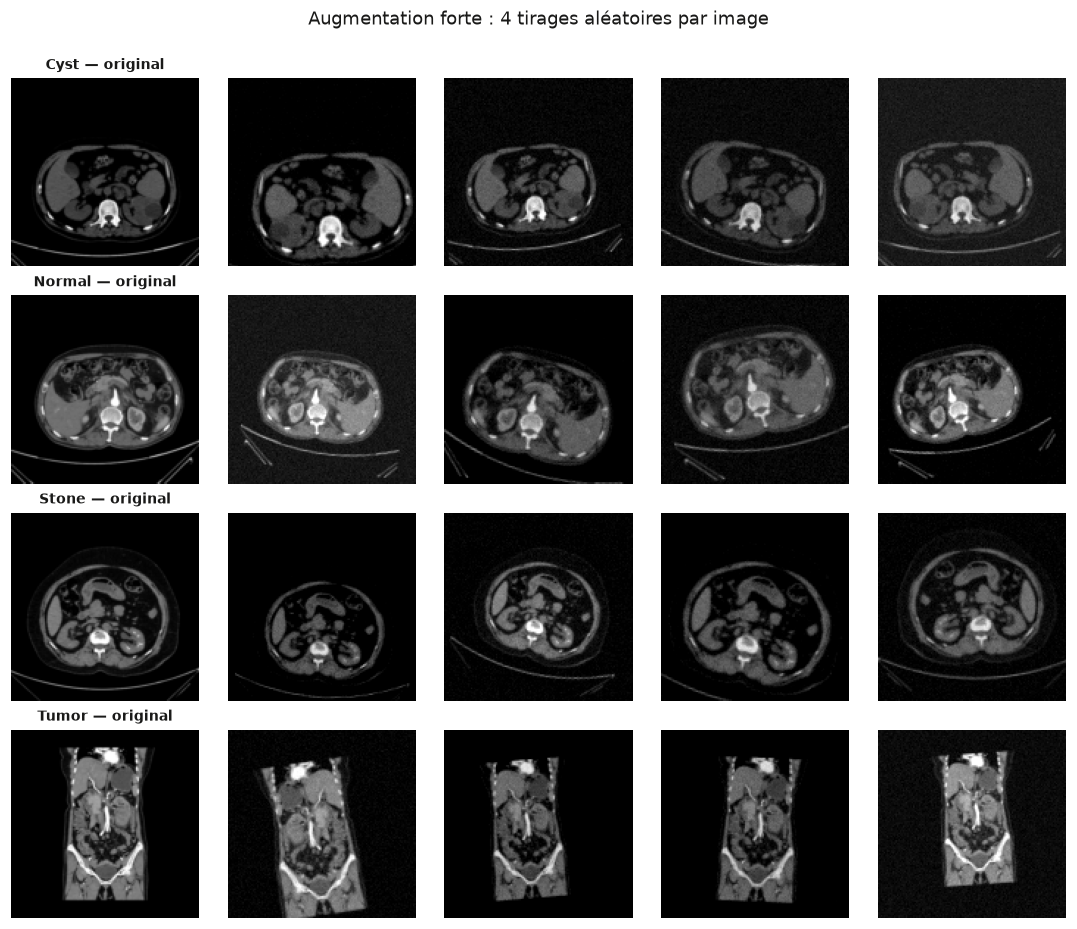

In [4]:
X_tr, y_tr = load_split("train", 128)
torch.manual_seed(0)
idx = [int(np.where(y_tr == k)[0][len(np.where(y_tr == k)[0]) // 2]) for k in range(len(CLASSES))]
x = torch.from_numpy(X_tr[idx]).unsqueeze(1).cuda().float() / 255
fig, axes = plt.subplots(len(idx), 5, figsize=(10, 2.1 * len(idx)))
for r in range(len(idx)):
    axes[r, 0].imshow(x[r, 0].cpu(), cmap="gray", vmin=0, vmax=1)
    axes[r, 0].set_title(f"{CLASSES[y_tr[idx[r]]]} — original", fontsize=9)
    for c in range(1, 5):
        axes[r, c].imshow(strong_augment(x[r:r + 1].clone())[0, 0].cpu(), cmap="gray", vmin=0, vmax=1)
for ax in axes.flat: ax.axis("off")
plt.suptitle("Augmentation forte : 4 tirages aléatoires par image", y=1.0); plt.tight_layout(); plt.show()

In [5]:
ALL["e1"] = run_step("e1")
show_step(ALL["e1"])

Run : results/m1-e1-regul-s42-v1  |  GPU : NVIDIA GeForce GTX 1650


Paramètres : 389,348


Epoch  1/30 | train loss 1.2572 acc 0.4901 | val loss 1.4561 acc 0.5050 f1 0.3982 | 11.2s


Epoch  2/30 | train loss 1.1359 acc 0.6056 | val loss 1.4486 acc 0.4435 f1 0.4212 | 10.7s


Epoch  3/30 | train loss 1.0943 acc 0.6430 | val loss 1.5855 acc 0.4855 f1 0.4420 | 10.7s


Epoch  4/30 | train loss 1.0594 acc 0.6539 | val loss 1.3552 acc 0.3356 f1 0.3241 | 10.7s


... (56 outputs left out)

Epoch 15/30 | train loss 0.6447 acc 0.9037 | val loss 1.7422 acc 0.4329 f1 0.3951 | 10.7s


Epoch 16/30 | train loss 0.6425 acc 0.9066 | val loss 1.6128 acc 0.5358 f1 0.4689 | 10.7s
Early stopping : pas d'amélioration du val f1_macro depuis 8 epochs
Meilleur val f1_macro : 0.5555 (epoch 8)


,run,epochs,val_f1_max,accuracy,f1_macro,recall_Cyst,recall_Normal,recall_Stone,recall_Tumor
seed,,,,,,,,,
42,m1-e1-regul-s42-v1,16,0.585,0.595,0.502,0.626,0.789,0.569,0.104
43,m1-e1-regul-s43-v1,27,0.713,0.719,0.700,0.963,0.701,0.716,0.420
44,m1-e1-regul-s44-v1,16,0.556,0.651,0.536,0.357,1.000,0.502,0.319


moyenne ± écart-type (test) :  accuracy 0.655±0.062   f1_macro 0.579±0.106


## Étape e2 — Recadrage sur le corps

Dans les images d'origine, une grande partie des pixels est du **fond noir** ou la **table du scanner**. Après
le resize en 128 px, les reins et les lésions n'occupent que quelques pixels.

`src.data.body_bbox` trouve la **plus grande zone claire connexe** (le corps) : seuillage, ouverture
morphologique pour la séparer de la table, puis boîte englobante + 3 % de marge. On recadre dessus **avant**
le padding carré et le resize : à résolution égale, le rein occupe beaucoup plus de pixels.

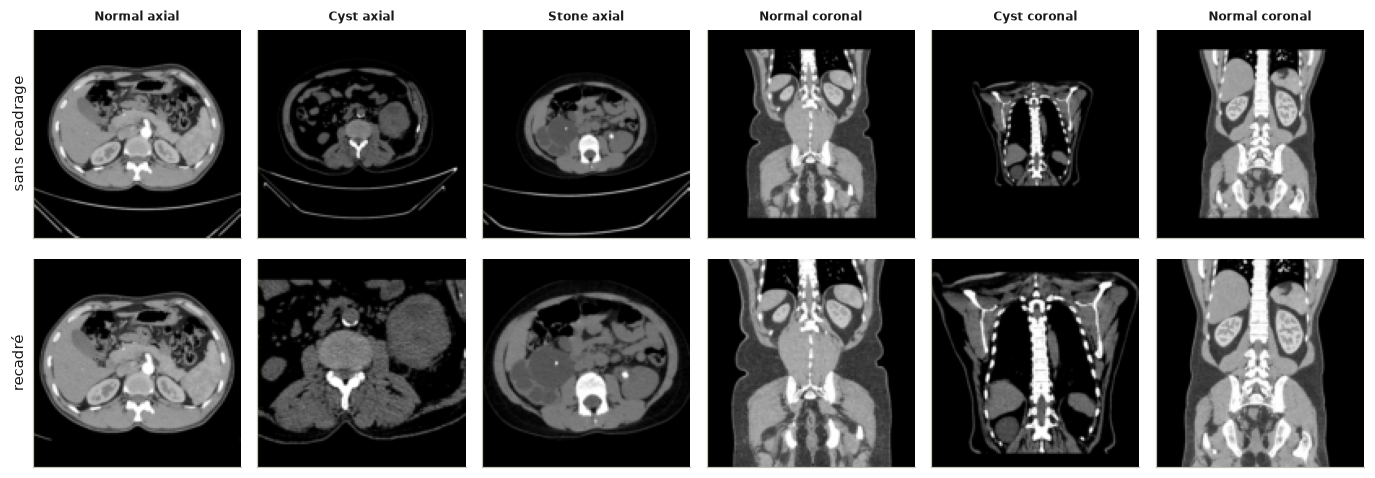

In [6]:
meta = pd.read_csv(DATA_DIR / "metadata.csv")
rng = np.random.RandomState(1)
rows = pd.concat([meta[meta.view == v].sample(3, random_state=rng) for v in ["axial", "coronal"]])
fig, axes = plt.subplots(2, len(rows), figsize=(2.1 * len(rows), 4.6))
for k, (_, r) in enumerate(rows.iterrows()):
    axes[0, k].imshow(preprocess_image(r.path, 128), cmap="gray"); axes[0, k].set_title(f"{r.cls} {r.view}", fontsize=8)
    axes[1, k].imshow(preprocess_image(r.path, 128, crop=True), cmap="gray")
for ax in axes.flat: ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
axes[0, 0].set_ylabel("sans recadrage"); axes[1, 0].set_ylabel("recadré")
plt.tight_layout(); plt.show()

In [7]:
X_full, _ = load_split("test", 128)
X_crop, _ = load_split("test", 128, crop=True)
print(f"Part de pixels « fond » (< 10) — sans recadrage : {(X_full < 10).mean():.1%}   recadré : {(X_crop < 10).mean():.1%}")

Part de pixels « fond » (< 10) — sans recadrage : 63.4%   recadré : 46.5%


In [8]:
ALL["e2"] = run_step("e2")
show_step(ALL["e2"])

Run : results/m1-e2-crop-s42-v1  |  GPU : NVIDIA GeForce GTX 1650


Paramètres : 389,348


Epoch  1/30 | train loss 1.2448 acc 0.4985 | val loss 1.4390 acc 0.4485 f1 0.3781 | 10.7s


Epoch  2/30 | train loss 1.1324 acc 0.6037 | val loss 1.4520 acc 0.4251 f1 0.3810 | 10.7s


Epoch  3/30 | train loss 1.0718 acc 0.6416 | val loss 1.4696 acc 0.5531 f1 0.4646 | 10.7s


Epoch  4/30 | train loss 1.0389 acc 0.6576 | val loss 1.6844 acc 0.3714 f1 0.2601 | 10.7s


... (75 outputs left out)

Epoch 24/30 | train loss 0.5436 acc 0.9684 | val loss 1.2558 acc 0.5721 f1 0.5657 | 10.9s


Epoch 25/30 | train loss 0.5390 acc 0.9702 | val loss 1.6590 acc 0.4715 f1 0.4559 | 10.8s
Early stopping : pas d'amélioration du val f1_macro depuis 8 epochs
Meilleur val f1_macro : 0.7071 (epoch 17)


,run,epochs,val_f1_max,accuracy,f1_macro,recall_Cyst,recall_Normal,recall_Stone,recall_Tumor
seed,,,,,,,,,
42,m1-e2-crop-s42-v1,24,0.695,0.706,0.679,0.914,0.733,0.831,0.269
43,m1-e2-crop-s43-v1,30,0.686,0.769,0.708,0.899,0.907,0.773,0.250
44,m1-e2-crop-s44-v1,25,0.707,0.767,0.672,0.805,0.984,0.773,0.190


moyenne ± écart-type (test) :  accuracy 0.747±0.036   f1_macro 0.686±0.019


## Étape e3 — MixUp / CutMix et sampler équilibré

- **MixUp** : on superpose deux images en transparence (`λ·A + (1-λ)·B`) et la cible devient le même mélange
  des deux labels. **CutMix** : on colle un rectangle de l'image B dans l'image A, et la cible est proportionnelle
  à la surface. Le modèle ne peut plus mémoriser une image précise et apprend des frontières de décision plus
  « douces ». Ici, 80 % des batches sont mélangés, moitié MixUp, moitié CutMix.
- **Sampler équilibré** : au lieu de pondérer la loss, on tire les images du train avec remise de sorte que
  chaque classe ait la même probabilité. Stone (11 % des données) apparaît donc dans ~25 % des exemples vus.
  On désactive `class_weights`, sinon la correction serait appliquée deux fois.

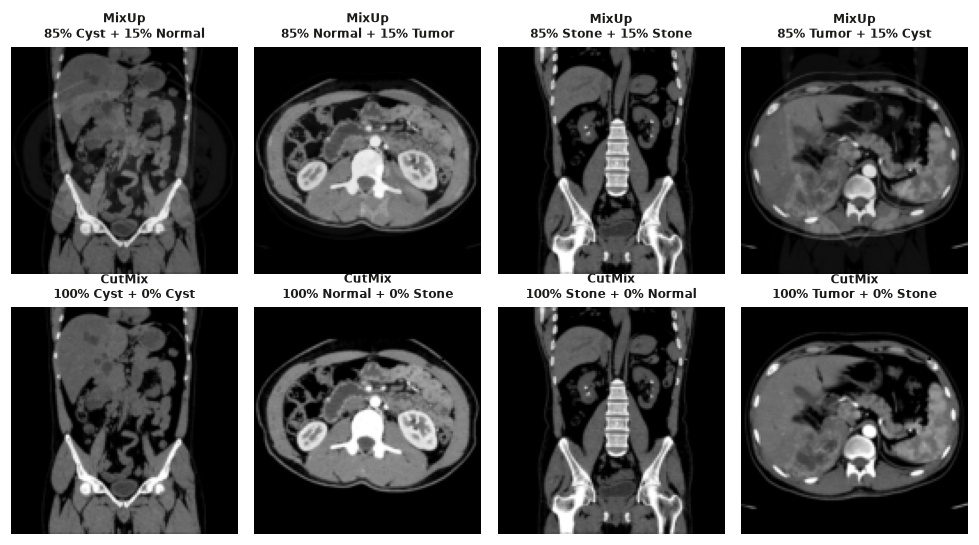

In [9]:
X_c, y_c = load_split("train", 128, crop=True)
torch.manual_seed(3)
pick = torch.tensor([int(np.where(y_c == k)[0][200]) for k in range(len(CLASSES))] * 2)
xb = torch.from_numpy(X_c[pick.numpy()]).unsqueeze(1).float() / 255
yb = torch.from_numpy(y_c[pick.numpy()])
fig, axes = plt.subplots(2, 4, figsize=(9, 5))
for row, cutmix_prob in enumerate([0.0, 1.0]):
    xm, ya, yb2, lam = mixup_cutmix(xb, yb, alpha=0.4, cutmix_prob=cutmix_prob)
    for k in range(4):
        ax = axes[row, k]; ax.imshow(xm[k, 0], cmap="gray", vmin=0, vmax=1); ax.axis("off")
        ax.set_title(f"{'MixUp' if cutmix_prob == 0 else 'CutMix'}\n{lam:.0%} {CLASSES[ya[k]]} + {1 - lam:.0%} {CLASSES[yb2[k]]}", fontsize=8)
plt.tight_layout(); plt.show()

In [10]:
from src.data import GpuLoader
dl = GpuLoader(X_c, y_c, 64, shuffle=True, device="cuda", balanced=True)
seen = torch.cat([yb for _, yb in dl]).cpu().numpy()
pd.DataFrame({"dans le train": np.bincount(y_c) / len(y_c), "vu pendant 1 epoch (sampler équilibré)": np.bincount(seen) / len(seen)},
             index=CLASSES).round(3)

,dans le train,vu pendant 1 epoch (sampler équilibré)
Cyst,0.277,0.250
Normal,0.422,0.243
Stone,0.115,0.254
Tumor,0.187,0.253


In [11]:
ALL["e3"] = run_step("e3")
show_step(ALL["e3"])

Run : results/m1-e3-mix-s42-v1  |  GPU : NVIDIA GeForce GTX 1650


Paramètres : 389,348


Epoch  1/30 | train loss 1.2668 acc 0.3915 | val loss 1.3142 acc 0.4955 f1 0.3889 | 10.7s


Epoch  2/30 | train loss 1.1831 acc 0.4609 | val loss 1.2624 acc 0.5129 f1 0.4501 | 10.5s


Epoch  3/30 | train loss 1.1410 acc 0.4853 | val loss 1.3351 acc 0.3266 f1 0.3025 | 10.5s


Epoch  4/30 | train loss 1.1037 acc 0.5225 | val loss 2.7334 acc 0.2271 f1 0.1035 | 10.5s


... (62 outputs left out)

Epoch 29/30 | train loss 0.7423 acc 0.7301 | val loss 0.9716 acc 0.6594 f1 0.6330 | 10.5s


Epoch 30/30 | train loss 0.7439 acc 0.7466 | val loss 0.9784 acc 0.6443 f1 0.6238 | 10.5s
Early stopping : pas d'amélioration du val f1_macro depuis 8 epochs
Meilleur val f1_macro : 0.6784 (epoch 22)


,run,epochs,val_f1_max,accuracy,f1_macro,recall_Cyst,recall_Normal,recall_Stone,recall_Tumor
seed,,,,,,,,,
42,m1-e3-mix-s42-v1,25,0.641,0.716,0.644,0.731,0.951,0.564,0.228
43,m1-e3-mix-s43-v1,9,0.414,0.548,0.357,0.366,0.943,0.000,0.198
44,m1-e3-mix-s44-v1,30,0.678,0.677,0.605,0.747,0.872,0.640,0.135


moyenne ± écart-type (test) :  accuracy 0.647±0.088   f1_macro 0.535±0.156


## Étape e4 — Architecture résiduelle (toujours from scratch)

Le baseline n'a qu'une convolution par résolution. On passe à des **blocs résiduels** (`src/model1.py`, `block: residual`) :
- 2 convolutions 3×3 par bloc, et un **raccourci** qui additionne l'entrée du bloc à sa sortie. Le gradient
  passe directement par ce raccourci, ce qui permet d'entraîner un réseau plus profond ;
- 5 étages au lieu de 4 (32 → 64 → 128 → 256 → 256 canaux) ;
- **Dropout2d** 0,1 dans chaque bloc : on éteint des cartes de features entières, une régularisation adaptée aux convolutions.

C'est la même idée que ResNet, mais **initialisée au hasard** : aucun poids pré-entraîné.

In [12]:
for step in ["e0", "e4"]:
    c = yaml.safe_load(Path(STEPS[step]).read_text())
    m = get_model(c["model"]["name"], n_classes=4, **c["model"].get("params", {}))
    print(f"{STEP_LABELS[step]:22s}: {sum(p.numel() for p in m.parameters()):>9,} paramètres, "
          f"{sum(isinstance(l, torch.nn.Conv2d) for l in m.modules())} convolutions")

e0 baseline           :   389,348 paramètres, 4 convolutions
e4 +résiduel          : 2,407,524 paramètres, 14 convolutions


In [13]:
ALL["e4"] = run_step("e4")
show_step(ALL["e4"])

Run : results/m1-e4-residual-s42-v1  |  GPU : NVIDIA GeForce GTX 1650


Paramètres : 2,407,524


Epoch  1/30 | train loss 1.4413 acc 0.3779 | val loss 1.2816 acc 0.3809 f1 0.3837 | 53.6s


Epoch  2/30 | train loss 1.2417 acc 0.4271 | val loss 1.2011 acc 0.6913 f1 0.5358 | 40.3s


Epoch  3/30 | train loss 1.1832 acc 0.4565 | val loss 1.1986 acc 0.4922 f1 0.4742 | 40.0s


Epoch  4/30 | train loss 1.0624 acc 0.5329 | val loss 1.2844 acc 0.4441 f1 0.4232 | 40.0s


... (77 outputs left out)

Epoch 19/30 | train loss 0.7160 acc 0.7470 | val loss 0.7569 acc 0.7936 f1 0.7362 | 39.6s


Epoch 20/30 | train loss 0.6887 acc 0.7240 | val loss 0.7686 acc 0.7947 f1 0.7414 | 39.6s
Early stopping : pas d'amélioration du val f1_macro depuis 8 epochs
Meilleur val f1_macro : 0.7738 (epoch 12)


,run,epochs,val_f1_max,accuracy,f1_macro,recall_Cyst,recall_Normal,recall_Stone,recall_Tumor
seed,,,,,,,,,
42,m1-e4-residual-s42-v1,29,0.817,0.812,0.736,0.860,0.999,0.862,0.266
43,m1-e4-residual-s43-v1,30,0.820,0.759,0.686,0.651,0.995,0.858,0.283
44,m1-e4-residual-s44-v1,20,0.774,0.731,0.654,0.563,0.960,0.862,0.335


moyenne ± écart-type (test) :  accuracy 0.767±0.041   f1_macro 0.692±0.041


## Bilan de l'ablation
### Moyenne ± écart-type sur 3 seeds (test)

In [14]:
res = pd.concat(ALL.values(), ignore_index=True)
cols = ["accuracy", "f1_macro"] + [f"recall_{c}" for c in CLASSES]
summary = res.groupby("step")[cols].agg(["mean", "std"])
table = pd.DataFrame({c: [f"{summary.loc[s, (c, 'mean')]:.3f} ± {summary.loc[s, (c, 'std')]:.3f}" for s in summary.index]
                      for c in cols}, index=[STEP_LABELS[s] for s in summary.index])
table

,accuracy,f1_macro,recall_Cyst,recall_Normal,recall_Stone,recall_Tumor
e0 baseline,0.725 ± 0.114,0.574 ± 0.153,0.826 ± 0.266,0.990 ± 0.009,0.523 ± 0.270,0.071 ± 0.074
e1 +régularisation,0.655 ± 0.062,0.579 ± 0.106,0.648 ± 0.304,0.830 ± 0.154,0.596 ± 0.109,0.281 ± 0.161
e2 +recadrage,0.747 ± 0.036,0.686 ± 0.019,0.873 ± 0.059,0.875 ± 0.129,0.793 ± 0.033,0.236 ± 0.042
e3 +MixUp/sampler,0.647 ± 0.088,0.535 ± 0.156,0.615 ± 0.215,0.922 ± 0.044,0.401 ± 0.350,0.187 ± 0.048
e4 +résiduel,0.767 ± 0.041,0.692 ± 0.041,0.691 ± 0.152,0.985 ± 0.022,0.861 ± 0.003,0.295 ± 0.036


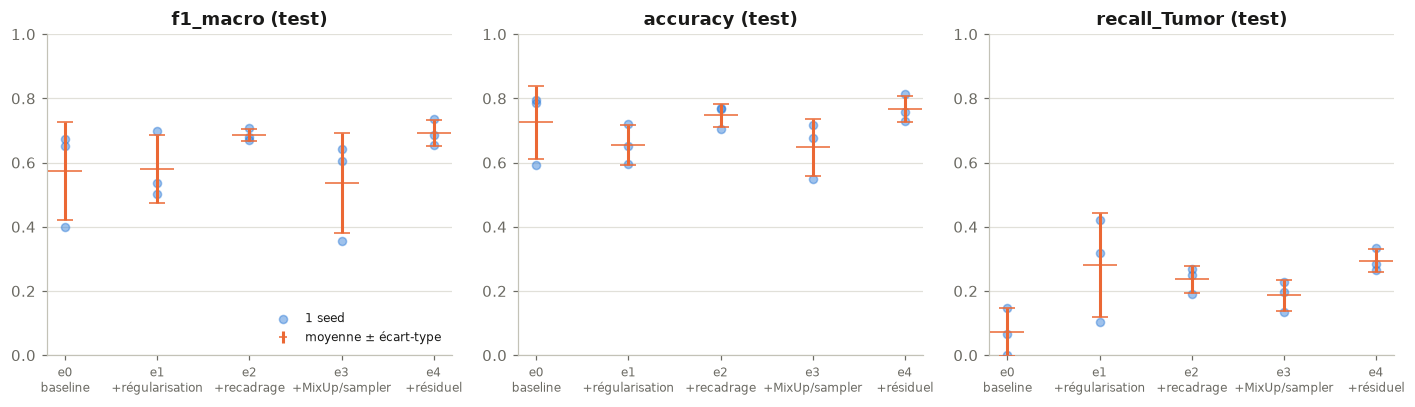

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=False)
steps = list(ALL)
for ax, metric in zip(axes, ["f1_macro", "accuracy", "recall_Tumor"]):
    for i, s in enumerate(steps):
        vals = res.loc[res.step == s, metric]
        ax.scatter([i] * len(vals), vals, s=28, color=SERIES[0], alpha=0.45, zorder=3)
        ax.errorbar(i, vals.mean(), yerr=vals.std(), fmt="_", markersize=22, color=SERIES[1], lw=2, capsize=5, zorder=4)
    ax.set_xticks(range(len(steps)), [STEP_LABELS[s].replace(" ", "\n", 1) for s in steps], fontsize=8)
    ax.set_title(f"{metric} (test)"); ax.set_ylim(0, 1); ax.grid(axis="x", visible=False)
axes[0].scatter([], [], s=28, color=SERIES[0], alpha=0.45, label="1 seed")
axes[0].errorbar([], [], yerr=[], fmt="_", color=SERIES[1], label="moyenne ± écart-type")
axes[0].legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

### Courbes de validation (seed 42)
L'écart entre le train et la validation montre l'effet de la régularisation sur le sur-apprentissage.

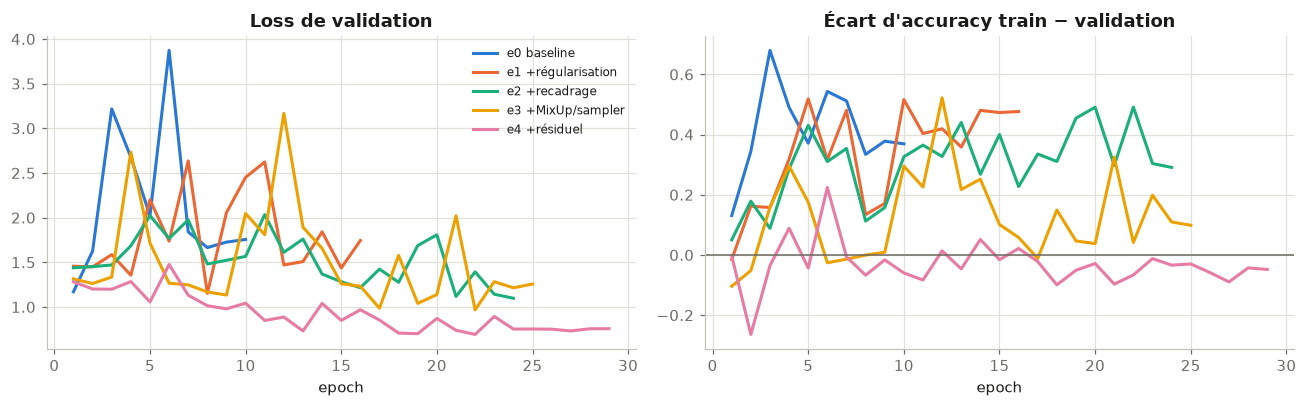

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for k, s in enumerate(steps):
    run_dir = Path("results") / res.loc[(res.step == s) & (res.seed == 42), "run"].iloc[0]
    tr, va = read_run(run_dir)
    axes[0].plot(va.epoch, va.loss, color=SERIES[k], label=STEP_LABELS[s])
    axes[1].plot(tr.epoch, tr.acc - va.acc, color=SERIES[k], label=STEP_LABELS[s])
axes[0].set_title("Loss de validation"); axes[1].set_title("Écart d'accuracy train − validation")
axes[1].axhline(0, color=INK_MUTED, lw=1)
for ax in axes: ax.set_xlabel("epoch")
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

## Analyse de la meilleure étape

On retient l'étape au **meilleur F1 macro moyen**. La matrice de confusion est **cumulée sur les 3 seeds** :
elle reflète le comportement typique de la configuration, pas un run chanceux.

Meilleure étape : e4 +résiduel  (configs/model1_ablation/e4_residual.yaml)


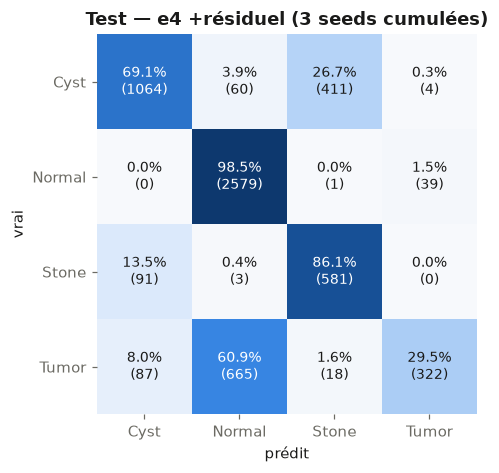

In [17]:
best_step = summary[("f1_macro", "mean")].idxmax()
best_runs = [Path("results") / r for r in res.loc[res.step == best_step, "run"]]
print(f"Meilleure étape : {STEP_LABELS[best_step]}  ({STEPS[best_step]})")
cm = sum(np.array(json.loads((r / "test_output.json").read_text())["confusion_matrix"]["matrix"]) for r in best_runs)
plot_confusion(cm, CLASSES, f"Test — {STEP_LABELS[best_step]} (3 seeds cumulées)"); plt.show()

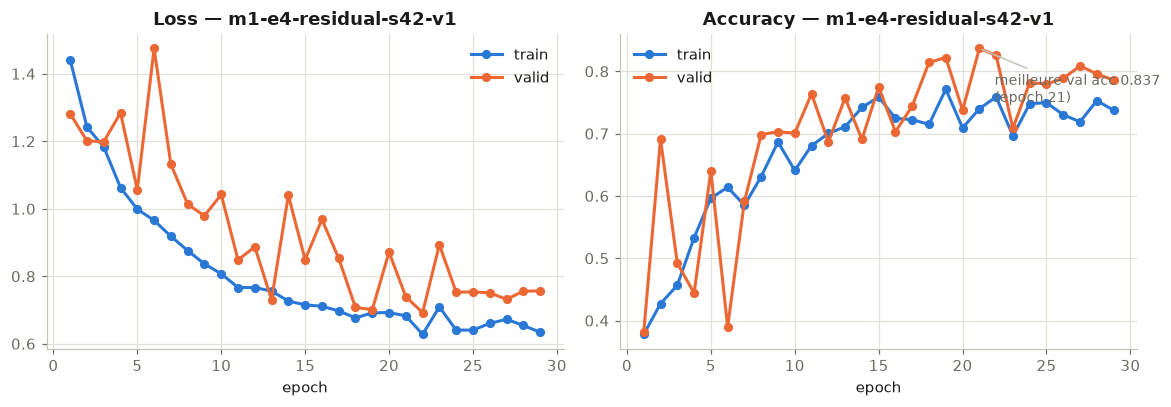

In [18]:
plot_curves(best_runs[0]); plt.show()

### Gains « gratuits » au moment de la prédiction

Sans réentraîner, deux astuces peuvent améliorer les prédictions :
- **TTA (test-time augmentation)** : on moyenne les probabilités de l'image et de sa version retournée.
- **Vote par série** : toutes les coupes d'un même examen reçoivent la classe moyenne prédite sur l'examen.
  C'est légitime en pratique, car un radiologue sait quelles coupes viennent du même examen, et c'est plus proche
  de l'usage médical (on diagnostique un examen, pas une coupe).

In [19]:
files = list_split_files("test")
meta_idx = meta.set_index(["cls", "filename"])
series = np.array([meta_idx.loc[(CLASSES[l], f.name), "series"] for f, l in files])

def series_vote(probs):
    df = pd.DataFrame(probs).assign(series=series)
    return df.groupby("series").transform("mean").to_numpy().argmax(1)

rows = []
for r in best_runs:
    y, p, pr = predict(r)
    _, p_tta, pr_tta = predict(r, tta=True)
    for name, pred in [("standard", p), ("TTA (flip)", p_tta), ("vote par série", series_vote(pr)),
                       ("TTA + vote par série", series_vote(pr_tta))]:
        rows.append({"run": r.name, "méthode": name, "accuracy": (pred == y).mean(),
                     "f1_macro": f1_score(y, pred, average="macro")})
pred_tab = pd.DataFrame(rows)
pred_tab.groupby("méthode", sort=False)[["accuracy", "f1_macro"]].agg(["mean", "std"]).round(3)

accuracy        f1_macro       
                         mean    std     mean    std
méthode                                             
standard                0.767  0.041    0.692  0.041
TTA (flip)              0.768  0.041    0.692  0.041
vote par série          0.791  0.052    0.723  0.064
TTA + vote par série    0.790  0.053    0.722  0.065

## Comparaison avec le modèle 2 (transfer learning)

In [20]:
rows = [{"modèle": STEP_LABELS[s], **res.loc[res.step == s, cols].mean().to_dict(), "runs": len(res[res.step == s])}
        for s in ["e0", best_step]]
for p in sorted(Path("results").glob("model2-v*/test_output.json")):
    o = json.loads(p.read_text())
    rows.append({"modèle": f"modèle 2 ResNet18 ({p.parent.name})", "accuracy": o["accuracy"], "f1_macro": o["f1_macro"],
                 **{f"recall_{c}": v["recall"] for c, v in o["per_class"].items()}, "runs": 1})
pd.DataFrame(rows).set_index("modèle").round(3)

,accuracy,f1_macro,recall_Cyst,recall_Normal,recall_Stone,recall_Tumor,runs
modèle,,,,,,,
e0 baseline,0.725,0.574,0.826,0.990,0.523,0.071,3
e4 +résiduel,0.767,0.692,0.691,0.985,0.861,0.295,3
modèle 2 ResNet18 (model2-v1),0.757,0.689,0.530,0.989,0.956,0.398,1


## Conclusions

Résultats du run complet (5 étapes × 3 seeds, test, moyenne ± écart-type) :

| étape | accuracy | F1 macro | rappel Stone | rappel Tumor |
|---|---|---|---|---|
| e0 baseline | 0,73 ± 0,11 | 0,57 ± 0,15 | 0,52 ± 0,27 | 0,07 ± 0,07 |
| e1 +régularisation | 0,66 ± 0,06 | 0,58 ± 0,11 | 0,60 ± 0,11 | 0,28 ± 0,16 |
| e2 +recadrage | 0,75 ± 0,04 | **0,69 ± 0,02** | 0,79 ± 0,03 | 0,24 ± 0,04 |
| e3 +MixUp/sampler | 0,65 ± 0,09 | 0,54 ± 0,16 | 0,40 ± 0,35 | 0,19 ± 0,05 |
| **e4 +résiduel** | **0,77 ± 0,04** | **0,69 ± 0,04** | **0,86 ± 0,00** | **0,30 ± 0,04** |

**Ce qui marche**
- **Le recadrage sur le corps (e2) est le changement le plus utile.** Le F1 macro passe de 0,58 à 0,69 et,
  surtout, l'écart-type tombe de 0,11 à 0,02 : les résultats ne dépendent presque plus de la seed. La part de fond
  dans l'image passe de 63 % à 47 %, donc le rein occupe plus de pixels à 128 px.
- **L'architecture résiduelle (e4) donne le meilleur modèle from scratch :** meilleure accuracy, rappel Stone de
  86 % stable sur les 3 seeds, Tumor à 30 %. Sa loss de validation est nettement plus basse et plus stable que
  celle de toutes les autres étapes.
- **Le vote par série** (sans réentraîner) ajoute environ +3 points de F1 (0,69 → 0,72). Le TTA par flip n'apporte rien.
- **Le meilleur modèle from scratch (e4) fait jeu égal avec le ResNet18 pré-entraîné** du notebook 04 (F1 0,69 dans les deux cas),
  avec 5× moins de paramètres. Le ResNet18 reste meilleur sur Stone et Tumor, mais il n'a qu'un seul run.

**Ce qui ne marche pas (encore)**
- **e1 seul n'améliore pas le F1** (0,58 contre 0,57) et fait baisser l'accuracy, même s'il réduit la variance et
  fait monter le rappel Tumor. L'augmentation n'est vraiment utile qu'une fois combinée au recadrage.
- **e3 (MixUp + sampler) est un recul**, à cause d'**une seed effondrée** (F1 0,36) : son meilleur epoch de validation
  est l'epoch 1, et l'early stopping l'a arrêtée à l'epoch 9.
- **Défaut de méthode identifié :** le learning rate (OneCycle) monte jusqu'à environ 30 % des epochs, soit l'epoch 9
  sur 30. Avec une patience de 8, l'early stopping peut couper un run **avant même la fin de la montée du learning rate**.
  C'est arrivé à e1 (2 seeds arrêtées à l'epoch 16) et à e3. Les étapes e1 et e3 sont donc probablement **sous-estimées**.
  Correction à faire : n'autoriser l'early stopping qu'après la montée du LR (option `min_epochs`), puis relancer e1–e4.
- **Le rappel Tumor reste faible** (30 %) : les tumeurs axiales sont confondues avec Normal, comme dans tous les modèles.
- Pour e3 et e4, l'accuracy de train est mesurée sur des images mélangées (MixUp/CutMix), ce qui explique l'écart
  train − validation négatif : ce n'est pas un vrai « meilleur en validation qu'en train ».

**Pistes suivantes**
1. Ajouter `min_epochs` (pas d'early stopping avant la fin de la montée du LR) et relancer l'ablation e1–e4.
2. Tester e4 **sans MixUp** (recadrage + régularisation + résiduel), pour savoir si e3 aide ou gêne vraiment.
3. Recadrage + résolution plus haute (192–224 px) avec l'architecture résiduelle.
4. Une focal loss pour cibler les tumeurs confondues avec Normal.